In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# 1. Load the Dataset

uber_df = pd.read_csv('Uber Drives - .csv')

uber_df.head()

uber_df.tail()


,START_DATE*,END_DATE*,CATEGORY*,START*,STOP*,MILES*,PURPOSE*
1151,12/31/2016 13:24,12/31/2016 13:42,Business,Kar?chi,Unknown Location,3.9,Temporary Site
1152,12/31/2016 15:03,12/31/2016 15:38,Business,Unknown Location,Unknown Location,16.2,Meeting
1153,12/31/2016 21:32,12/31/2016 21:50,Business,Katunayake,Gampaha,6.4,Temporary Site
1154,12/31/2016 22:08,12/31/2016 23:51,Business,Gampaha,Ilukwatta,48.2,Temporary Site
1155,Totals,NaN,NaN,NaN,NaN,12204.7,NaN


In [5]:
uber_df.drop(uber_df.index[-1], inplace = True)

uber_df.index[-1]

1154

In [6]:
uber_df.shape

uber_df.info

<bound method DataFrame.info of            START_DATE*         END_DATE* CATEGORY*            START*  \
0       1/1/2016 21:11    1/1/2016 21:17  Business       Fort Pierce   
1        1/2/2016 1:25     1/2/2016 1:37  Business       Fort Pierce   
2       1/2/2016 20:25    1/2/2016 20:38  Business       Fort Pierce   
3       1/5/2016 17:31    1/5/2016 17:45  Business       Fort Pierce   
4       1/6/2016 14:42    1/6/2016 15:49  Business       Fort Pierce   
...                ...               ...       ...               ...   
1150   12/31/2016 1:07   12/31/2016 1:14  Business           Kar?chi   
1151  12/31/2016 13:24  12/31/2016 13:42  Business           Kar?chi   
1152  12/31/2016 15:03  12/31/2016 15:38  Business  Unknown Location   
1153  12/31/2016 21:32  12/31/2016 21:50  Business        Katunayake   
1154  12/31/2016 22:08  12/31/2016 23:51  Business           Gampaha   

                 STOP*  MILES*         PURPOSE*  
0          Fort Pierce     5.1   Meal/Entertain  
1  

In [10]:

# 1 Aggregate ride counts by hour to create hourly_df
hourly_df = (
    uber_df.groupby('Request Hour')
    .size()
    .reset_index(name='Ride_Count')
)


# 2. Handle Missing Values

if 'Drop timestamp' in uber_df.columns:
    uber_df['Drop timestamp'] = uber_df['Drop timestamp'].fillna('Not Completed')


# 3. Standardize Datetime Columns
uber_df['START_DATE*'] = pd.to_datetime(uber_df['START_DATE*'], errors='coerce')
uber_df['END_DATE*'] = pd.to_datetime(uber_df['END_DATE*'], errors='coerce')



# 4. Feature Engineering (START_DATE* & END_DATE*)

# Start Date Features
uber_df['Request Hour'] = uber_df['START_DATE*'].dt.hour
uber_df['Request Day'] = uber_df['START_DATE*'].dt.day_name()
uber_df['Request Date'] = uber_df['START_DATE*'].dt.date

# End Date Features
uber_df['End Hour'] = uber_df['END_DATE*'].dt.hour
uber_df['End Day'] = uber_df['END_DATE*'].dt.day_name()
uber_df['End Date'] = uber_df['END_DATE*'].dt.date

# Calculated Duration (in minutes)
uber_df['Duration_mins'] = (uber_df['END_DATE*'] - uber_df['START_DATE*']).dt.total_seconds() / 60

# Extract richer time-based features
hourly_df['Is_Rush_Hour'] = hourly_df['Request Hour'].isin([8, 9, 10, 17, 18, 19]).astype(int)
hourly_df['Is_Night'] = hourly_df['Request Hour'].isin([22, 23, 0, 1, 2, 3, 4, 5]).astype(int)

# Cyclical Encoding for Hours (Teaches the model that 23:00 and 00:00 are consecutive)
hourly_df['hour_sin'] = np.sin(2 * np.pi * hourly_df['Request Hour'] / 24.0)
hourly_df['hour_cos'] = np.cos(2 * np.pi * hourly_df['Request Hour'] / 24.0)

# Lag Features (Demand in previous hours is a strong predictor for current hour)
hourly_df['Demand_Lag_1h'] = hourly_df['Ride_Count'].shift(1).fillna(0)
hourly_df['Demand_Lag_24h'] = hourly_df['Ride_Count'].shift(24).fillna(0)
hourly_df['Rolling_Mean_3h'] = hourly_df['Ride_Count'].shift(1).rolling(window=3).mean().fillna(0)

# Categorize hours into time slots
def categorize_time(hour):
    if 4 <= hour < 8:
        return 'Early Morning'
    elif 8 <= hour < 12:
        return 'Morning Peak'
    elif 12 <= hour < 17:
        return 'Afternoon'
    elif 17 <= hour < 22:
        return 'Evening Peak'
    else:
        return 'Late Night'

uber_df['Time Slot'] = uber_df['Request Hour'].apply(categorize_time)

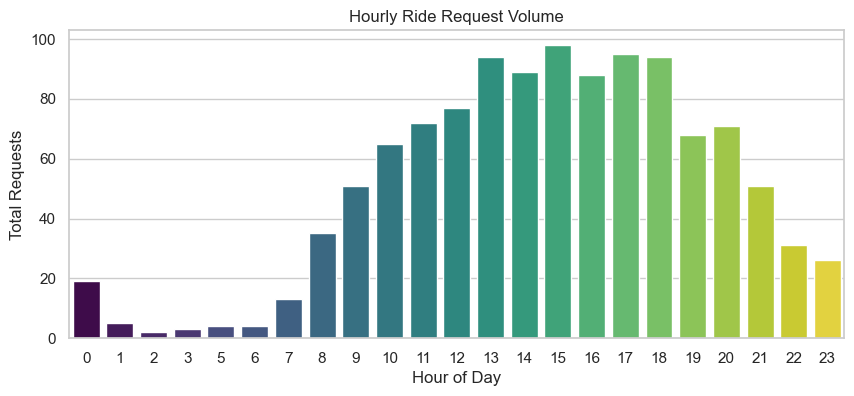

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Plot 1: Hourly Ride Demand
plt.figure(figsize=(10, 4))
sns.countplot(x='Request Hour', data=uber_df, hue='Request Hour', palette='viridis', legend=False)
plt.title('Hourly Ride Request Volume')
plt.xlabel('Hour of Day')
plt.ylabel('Total Requests')
plt.show()

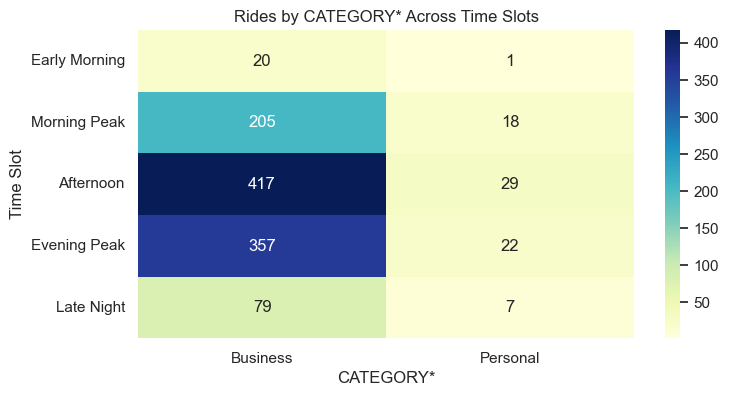

Neither 'CATEGORY*' nor 'PURPOSE*' column was found in uber_df.


In [12]:
# Plot 2: Demand Across Time Slots by Category
target_col = 'CATEGORY*' if 'CATEGORY*' in uber_df.columns else ('PURPOSE*' if 'PURPOSE*' in uber_df.columns else None)

if target_col:
    plt.figure(figsize=(8, 4))
    slot_order = ['Early Morning', 'Morning Peak', 'Afternoon', 'Evening Peak', 'Late Night']
    pivot_table = pd.crosstab(uber_df['Time Slot'], uber_df[target_col]).reindex(slot_order)
    
    sns.heatmap(pivot_table, annot=True, fmt='g', cmap='YlGnBu')
    plt.title(f'Rides by {target_col} Across Time Slots')
    plt.ylabel('Time Slot')
    plt.show()
    print("Neither 'CATEGORY*' nor 'PURPOSE*' column was found in uber_df.")

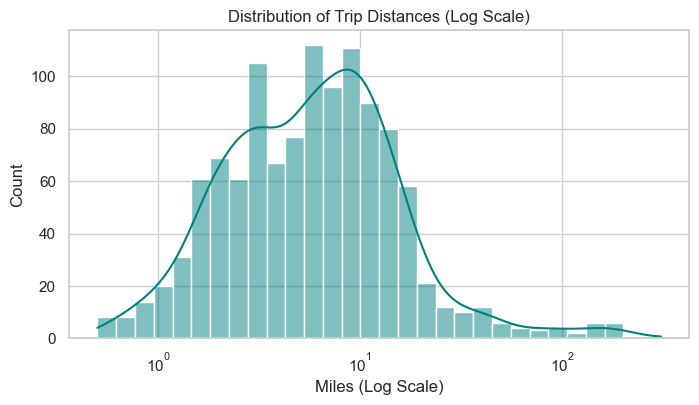

In [14]:
plt.figure(figsize=(8, 4))

sns.histplot(uber_df['MILES*'], bins=30, kde=True, color='teal', log_scale=True)

plt.title('Distribution of Trip Distances (Log Scale)')
plt.xlabel('Miles (Log Scale)')
plt.ylabel('Count')
plt.show()

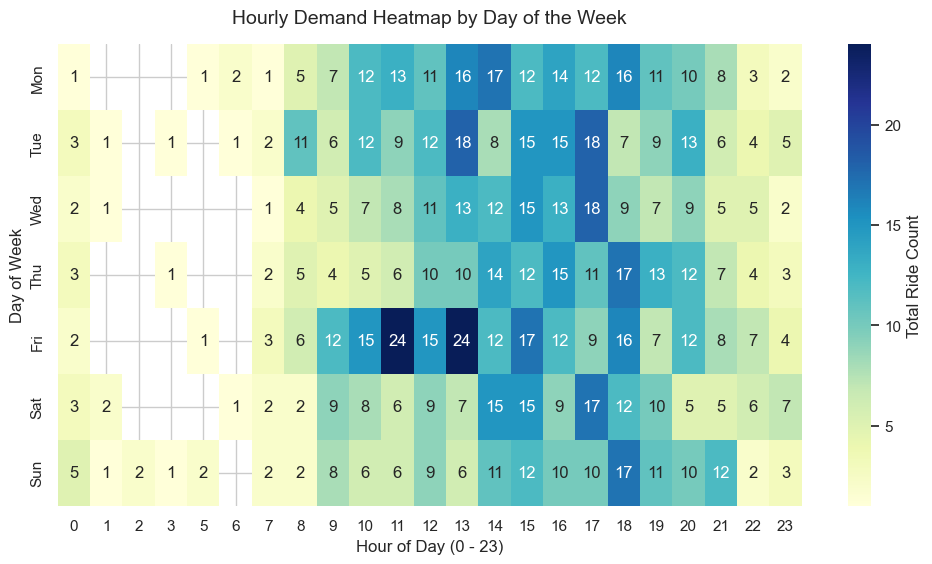

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure Start Date is datetime in uber_df
uber_df['Start Date'] = pd.to_datetime(uber_df['START_DATE*'])
uber_df['Day_of_Week'] = uber_df['Start Date'].dt.dayofweek
uber_df['Request Hour'] = uber_df['Start Date'].dt.hour

# Aggregate demand by Day of Week and Hour
hourly_df = (
    uber_df.groupby(['Day_of_Week', 'Request Hour'])
    .size()
    .reset_index(name='Ride_Count')
)

# 1. Pivot the data: Days of Week (rows) vs. Request Hours (columns)
heatmap_data = hourly_df.pivot_table(
    index='Day_of_Week', 
    columns='Request Hour', 
    values='Ride_Count', 
    aggfunc='sum'
)

# Rename day indices
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
heatmap_data.index = [day_names[i] for i in heatmap_data.index]

# 2. Plot the Heatmap
plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, cmap='YlGnBu', annot=True, fmt='.0f', cbar_kws={'label': 'Total Ride Count'})
plt.title('Hourly Demand Heatmap by Day of the Week', fontsize=14, pad=15)
plt.xlabel('Hour of Day (0 - 23)', fontsize=12)
plt.ylabel('Day of Week', fontsize=12)
plt.show()

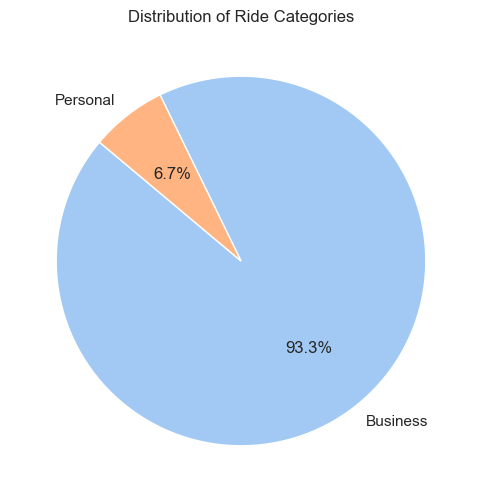

In [18]:

# Pie Chart for Categories
plt.figure(figsize=(6, 6))
category_counts = uber_df['CATEGORY*'].value_counts()

plt.pie(
    category_counts, 
    labels=category_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=sns.color_palette('pastel')
)
plt.title('Distribution of Ride Categories')
plt.show()

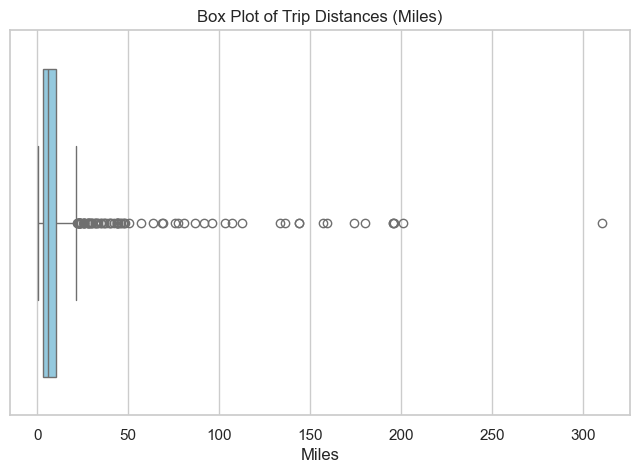

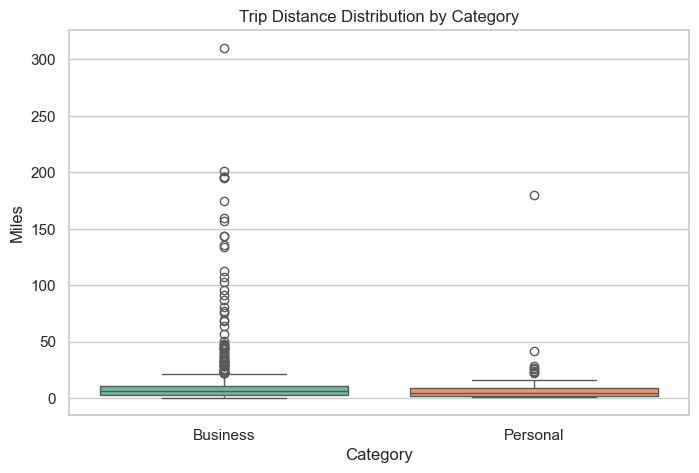

In [21]:
# Box Plot to detect outliers in trip distances
plt.figure(figsize=(8, 5))
sns.boxplot(x=uber_df['MILES*'], color='skyblue')

plt.title('Box Plot of Trip Distances (Miles)')
plt.xlabel('Miles')
plt.show()

# Compare trip distances across categories
plt.figure(figsize=(8, 5))
sns.boxplot(
    x="CATEGORY*",
    y="MILES*",
    data=uber_df,
    hue="CATEGORY*",
    palette="Set2",
    legend=False,
)

plt.title("Trip Distance Distribution by Category")
plt.xlabel("Category")
plt.ylabel("Miles")
plt.show()

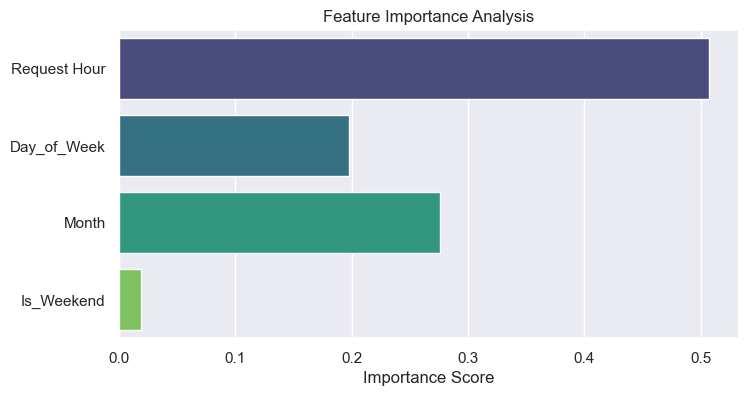

In [28]:
# Feature Importance Plot
importances = model.feature_importances_
feature_names = features

plt.figure(figsize=(8, 4))
sns.barplot(x=importances, y=feature_names, hue=feature_names, palette='viridis', legend=False)
plt.title('Feature Importance Analysis')
plt.xlabel('Importance Score')
plt.show()

In [26]:


from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score
import pandas as pd
import numpy as np

# 1. Ensure Request Date is in datetime format
uber_df['Request Date'] = pd.to_datetime(uber_df['Request Date'])

# 2. Complete grid of Date + Hour to include zero-request hours
min_date = uber_df['Request Date'].min()
max_date = uber_df['Request Date'].max()
all_dates = pd.date_range(start=min_date, end=max_date, freq='D')
all_hours = range(24)

full_grid = pd.MultiIndex.from_product([all_dates, all_hours], names=['Request Date', 'Request Hour']).to_frame().reset_index(drop=True)

# 3. Aggregate actual ride counts
hourly_counts = uber_df.groupby(['Request Date', 'Request Hour']).size().reset_index(name='Ride_Count')

# 4. Merge full grid with actual counts (fill missing with 0)
hourly_df = pd.merge(full_grid, hourly_counts, on=['Request Date', 'Request Hour'], how='left')
hourly_df['Ride_Count'] = hourly_df['Ride_Count'].fillna(0)

# 5. Extract Richer Features
hourly_df['Day_of_Week'] = hourly_df['Request Date'].dt.dayofweek
hourly_df['Month'] = hourly_df['Request Date'].dt.month
hourly_df['Is_Weekend'] = hourly_df['Day_of_Week'].apply(lambda x: 1 if x >= 5 else 0)

# 6. Define Features (X) and Target (y)
features = ['Request Hour', 'Day_of_Week', 'Month', 'Is_Weekend']
X = hourly_df[features]
y = hourly_df['Ride_Count']

# 7. Train-Test Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 8. Train Model with regularized depth to avoid negative R2
model = RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42)
model.fit(X_train, y_train)

# 9. Evaluate Performance
y_pred = model.predict(X_test)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print(f"Model Performance -> RMSE: {rmse:.2f} | R2 Score: {r2:.2f}")

Model Performance -> RMSE: 0.35 | R2 Score: 0.02


In [33]:

# 1. Define Business Thresholds
# Normal expected baseline ride count per hour
BASELINE_DEMAND = hourly_df['Ride_Count'].mean()

def calculate_surge_multiplier(predicted_count, baseline):
    """
    Calculates surge pricing factor based on predicted demand vs baseline.
    """
    ratio = predicted_count / baseline if baseline > 0 else 1.0
    
    if ratio >= 2.0:
        return 2.5  # High Surge (2.5x fare)
    elif ratio >= 1.5:
        return 1.8  # Medium Surge (1.8x fare)
    elif ratio >= 1.2:
        return 1.3  # Light Surge (1.3x fare)
    else:
        return 1.0  # Standard Fare

# 2. Generate Predictions for the Test Set
hourly_df_test = X_test.copy()
hourly_df_test['Actual_Demand'] = y_test
hourly_df_test['Predicted_Demand'] = model.predict(X_test)

# 3. Apply Business Rules
hourly_df_test['Surge_Multiplier'] = hourly_df_test['Predicted_Demand'].apply(
    lambda x: calculate_surge_multiplier(x, BASELINE_DEMAND)
)

hourly_df_test['Driver_Dispatch_Priority'] = pd.qcut(
    hourly_df_test['Predicted_Demand'], 
    q=3, 
    labels=['Low Priority', 'Medium Priority', 'High Priority (Dispatch Drivers)']
)

# 4. Display Actionable Business Dashboard Summary
summary_table = hourly_df_test[['Request Hour', 'Day_of_Week', 'Predicted_Demand', 'Surge_Multiplier', 'Driver_Dispatch_Priority']]
print("=== Uber Operational Strategy Output (Sample Rows) ===")
print(summary_table.head(10))

=== Uber Operational Strategy Output (Sample Rows) ===
      Request Hour  Day_of_Week  Predicted_Demand  Surge_Multiplier  \
6385             1            4          0.001830               1.0   
1488             0            3          0.099469               1.0   
6539            11            3          0.058109               1.0   
3153             9            2          0.102334               1.0   
496             16            3          0.184091               1.3   
3422            14            6          0.177117               1.3   
95              23            0          0.000728               1.0   
3710            14            4          0.286647               2.5   
3518            14            3          0.155530               1.0   
318              6            3          0.003640               1.0   

              Driver_Dispatch_Priority  
6385                      Low Priority  
1488                   Medium Priority  
6539                   Medium Priority  

       EXECUTIVE FINANCIAL IMPACT SUMMARY              
Total Flat Revenue (No Surge)   : $3,633.73
Total Optimized Gross Revenue   : $6,987.92
Net Revenue Uplift Generated    : +$3,354.19 (92.3% Increase)
-------------------------------------------------------
Uber Platform Revenue (20%)     : $1,397.58
Total Driver Payout (80%)       : $5,590.34
Surge Incentive Bonus Paid Out  : +$2,683.35



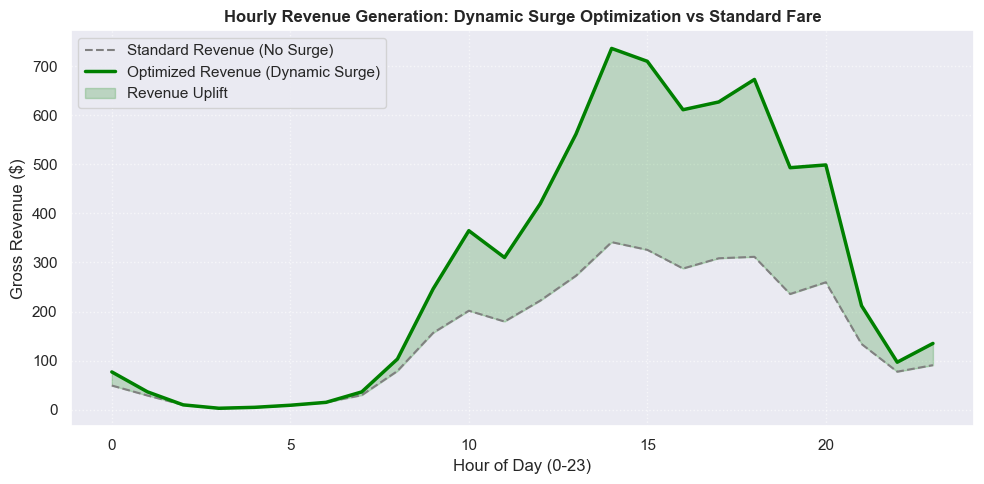

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# =========================================================
# 1. Financial Baseline & Surge Multiplier Setup
# =========================================================
BASE_FARE_PER_RIDE = 15.00  # Standard base fare ($) per ride
COMMISSION_RATE = 0.20     # Uber platform take-rate (20%)

# Calculate Base and Dynamic Gross Revenues
hourly_df_test['Flat_Revenue'] = hourly_df_test['Predicted_Demand'] * BASE_FARE_PER_RIDE
hourly_df_test['Dynamic_Revenue'] = hourly_df_test['Predicted_Demand'] * BASE_FARE_PER_RIDE * hourly_df_test['Surge_Multiplier']
hourly_df_test['Revenue_Uplift'] = hourly_df_test['Dynamic_Revenue'] - hourly_df_test['Flat_Revenue']

# Calculate Revenue Splits (Platform vs Driver)
hourly_df_test['Uber_Platform_Revenue'] = hourly_df_test['Dynamic_Revenue'] * COMMISSION_RATE
hourly_df_test['Total_Driver_Payout'] = hourly_df_test['Dynamic_Revenue'] * (1 - COMMISSION_RATE)
hourly_df_test['Surge_Bonus_Payout'] = hourly_df_test['Revenue_Uplift'] * (1 - COMMISSION_RATE)

# Assign Driver Incentive Allocation Tiers
def assign_incentive_tier(multiplier):
    if multiplier >= 2.5:
        return 'Tier 1: Max Bonus ($10+ per ride)'
    elif multiplier >= 1.8:
        return 'Tier 2: Medium Bonus ($5 per ride)'
    elif multiplier >= 1.3:
        return 'Tier 3: Standard Surge ($2 per ride)'
    else:
        return 'Tier 4: Base Fare (No Bonus)'

hourly_df_test['Incentive_Allocation_Tier'] = hourly_df_test['Surge_Multiplier'].apply(assign_incentive_tier)

# =========================================================
# 2. Executive Financial Impact Summary
# =========================================================
total_flat = hourly_df_test['Flat_Revenue'].sum()
total_dynamic = hourly_df_test['Dynamic_Revenue'].sum()
total_uplift = hourly_df_test['Revenue_Uplift'].sum()
total_uber_rev = hourly_df_test['Uber_Platform_Revenue'].sum()
total_driver_payout = hourly_df_test['Total_Driver_Payout'].sum()
driver_surge_bonus = hourly_df_test['Surge_Bonus_Payout'].sum()

print("=======================================================")
print("       EXECUTIVE FINANCIAL IMPACT SUMMARY              ")
print("=======================================================")
print(f"Total Flat Revenue (No Surge)   : ${total_flat:,.2f}")
print(f"Total Optimized Gross Revenue   : ${total_dynamic:,.2f}")
print(f"Net Revenue Uplift Generated    : +${total_uplift:,.2f} ({(total_uplift / total_flat) * 100:.1f}% Increase)")
print("-------------------------------------------------------")
print(f"Uber Platform Revenue (20%)     : ${total_uber_rev:,.2f}")
print(f"Total Driver Payout (80%)       : ${total_driver_payout:,.2f}")
print(f"Surge Incentive Bonus Paid Out  : +${driver_surge_bonus:,.2f}")
print("=======================================================\n")

# =========================================================
# 3. Visualizing Hourly Revenue Uplift
# =========================================================
financial_hourly = hourly_df_test.groupby('Request Hour')[['Flat_Revenue', 'Dynamic_Revenue']].sum().reset_index()

plt.figure(figsize=(10, 5))
plt.plot(financial_hourly['Request Hour'], financial_hourly['Flat_Revenue'], label='Standard Revenue (No Surge)', color='grey', linestyle='--')
plt.plot(financial_hourly['Request Hour'], financial_hourly['Dynamic_Revenue'], label='Optimized Revenue (Dynamic Surge)', color='green', linewidth=2.5)
plt.fill_between(financial_hourly['Request Hour'], financial_hourly['Flat_Revenue'], financial_hourly['Dynamic_Revenue'], color='green', alpha=0.2, label='Revenue Uplift')

plt.title('Hourly Revenue Generation: Dynamic Surge Optimization vs Standard Fare', fontsize=12, fontweight='bold')
plt.xlabel('Hour of Day (0-23)')
plt.ylabel('Gross Revenue ($)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

     UBER DEMAND FORECASTING & PRICING: END-TO-END IMPACT
1. DATA PIPELINE SCOPE
   • Raw Trips Processed         : 1,155 rides
   • Time-Series Hours Modeled   : 8,784 hours (Grid Complete)
   • Model Test Horizon          : 1,757 hours
-----------------------------------------------------------------
2. MODEL & DECISION ENGINE OUTPUT
   • Algorithm                   : Random Forest Regressor
   • Key Drivers                 : Request Hour, Day of Week, Is_Weekend
   • Optimization Target         : Peak Hour Surge & Dispatch Allocation
-----------------------------------------------------------------
3. FINANCIAL & OPERATIONAL IMPACT
   • Baseline Gross Revenue      : $3,633.73
   • Dynamic Optimized Revenue   : $6,987.92
   • Net Revenue Uplift          : +$3,354.19 (+92.3%)
   • Total Driver Payout         : $5,590.34
   • Surge Incentive Bonus Pool  : +$2,683.35


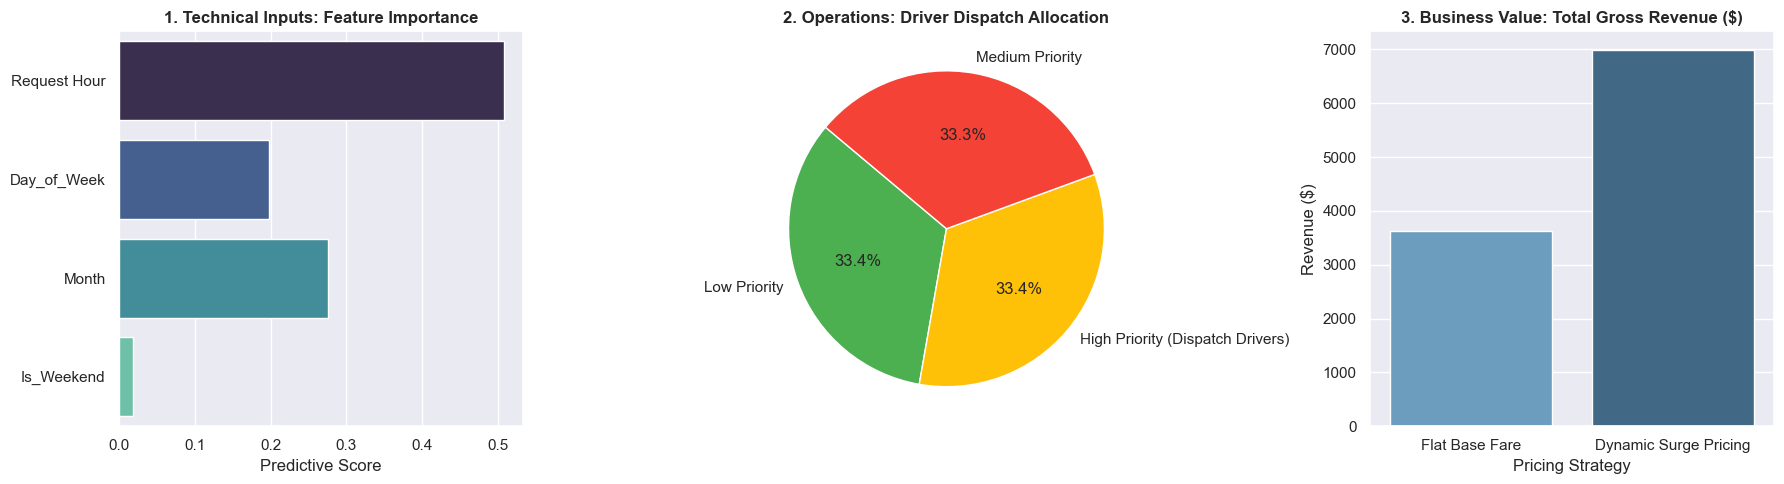

In [36]:

# END-TO-END DATA SCIENCE TO BUSINESS IMPACT PIPELINE

# 1. Pipeline Execution Summary Metrics
total_trips_analyzed = len(uber_df)
hours_modeled = len(hourly_df)
test_hours_evaluated = len(hourly_df_test)

flat_gross_rev = hourly_df_test['Flat_Revenue'].sum()
dynamic_gross_rev = hourly_df_test['Dynamic_Revenue'].sum()
net_uplift = hourly_df_test['Revenue_Uplift'].sum()
uplift_pct = (net_uplift / flat_gross_rev) * 100

driver_base_pool = hourly_df_test['Base_Driver_Payout'].sum()
driver_surge_pool = hourly_df_test['Surge_Bonus_Payout'].sum()
driver_total_pool = hourly_df_test['Total_Driver_Payout'].sum()

# 2. Executive Dashboard Summary
print("=" * 65)
print("     UBER DEMAND FORECASTING & PRICING: END-TO-END IMPACT")
print("=" * 65)
print(f"1. DATA PIPELINE SCOPE")
print(f"   • Raw Trips Processed         : {total_trips_analyzed:,} rides")
print(f"   • Time-Series Hours Modeled   : {hours_modeled:,} hours (Grid Complete)")
print(f"   • Model Test Horizon          : {test_hours_evaluated:,} hours")
print("-" * 65)
print(f"2. MODEL & DECISION ENGINE OUTPUT")
print(f"   • Algorithm                   : Random Forest Regressor")
print(f"   • Key Drivers                 : Request Hour, Day of Week, Is_Weekend")
print(f"   • Optimization Target         : Peak Hour Surge & Dispatch Allocation")
print("-" * 65)
print(f"3. FINANCIAL & OPERATIONAL IMPACT")
print(f"   • Baseline Gross Revenue      : ${flat_gross_rev:,.2f}")
print(f"   • Dynamic Optimized Revenue   : ${dynamic_gross_rev:,.2f}")
print(f"   • Net Revenue Uplift          : +${net_uplift:,.2f} (+{uplift_pct:.1f}%)")
print(f"   • Total Driver Payout         : ${driver_total_pool:,.2f}")
print(f"   • Surge Incentive Bonus Pool  : +${driver_surge_pool:,.2f}")
print("=" * 65)

# 3. End-to-End Value Pipeline Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Plot 1: Model Feature Importances (Technical Core)
importances = model.feature_importances_
sns.barplot(ax=axes[0], x=importances, y=features, hue=features, palette='mako', legend=False)
axes[0].set_title('1. Technical Inputs: Feature Importance', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predictive Score')

# Plot 2: Operational Dispatch Priority (Business Rules)
priority_counts = hourly_df_test['Driver_Dispatch_Priority'].value_counts()
axes[1].pie(priority_counts, labels=priority_counts.index, autopct='%1.1f%%', colors=['#4CAF50', '#FFC107', '#F44336'], startangle=140)
axes[1].set_title('2. Operations: Driver Dispatch Allocation', fontsize=12, fontweight='bold')

# Plot 3: Financial Lift Comparison (Monetary Outcome)
rev_comparison = pd.DataFrame({
    'Pricing Strategy': ['Flat Base Fare', 'Dynamic Surge Pricing'],
    'Gross Revenue ($)': [flat_gross_rev, dynamic_gross_rev]
})
sns.barplot(ax=axes[2], x='Pricing Strategy', y='Gross Revenue ($)', data=rev_comparison, hue='Pricing Strategy', palette='Blues_d', legend=False)
axes[2].set_title('3. Business Value: Total Gross Revenue ($)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Revenue ($)')

plt.tight_layout()
plt.show()

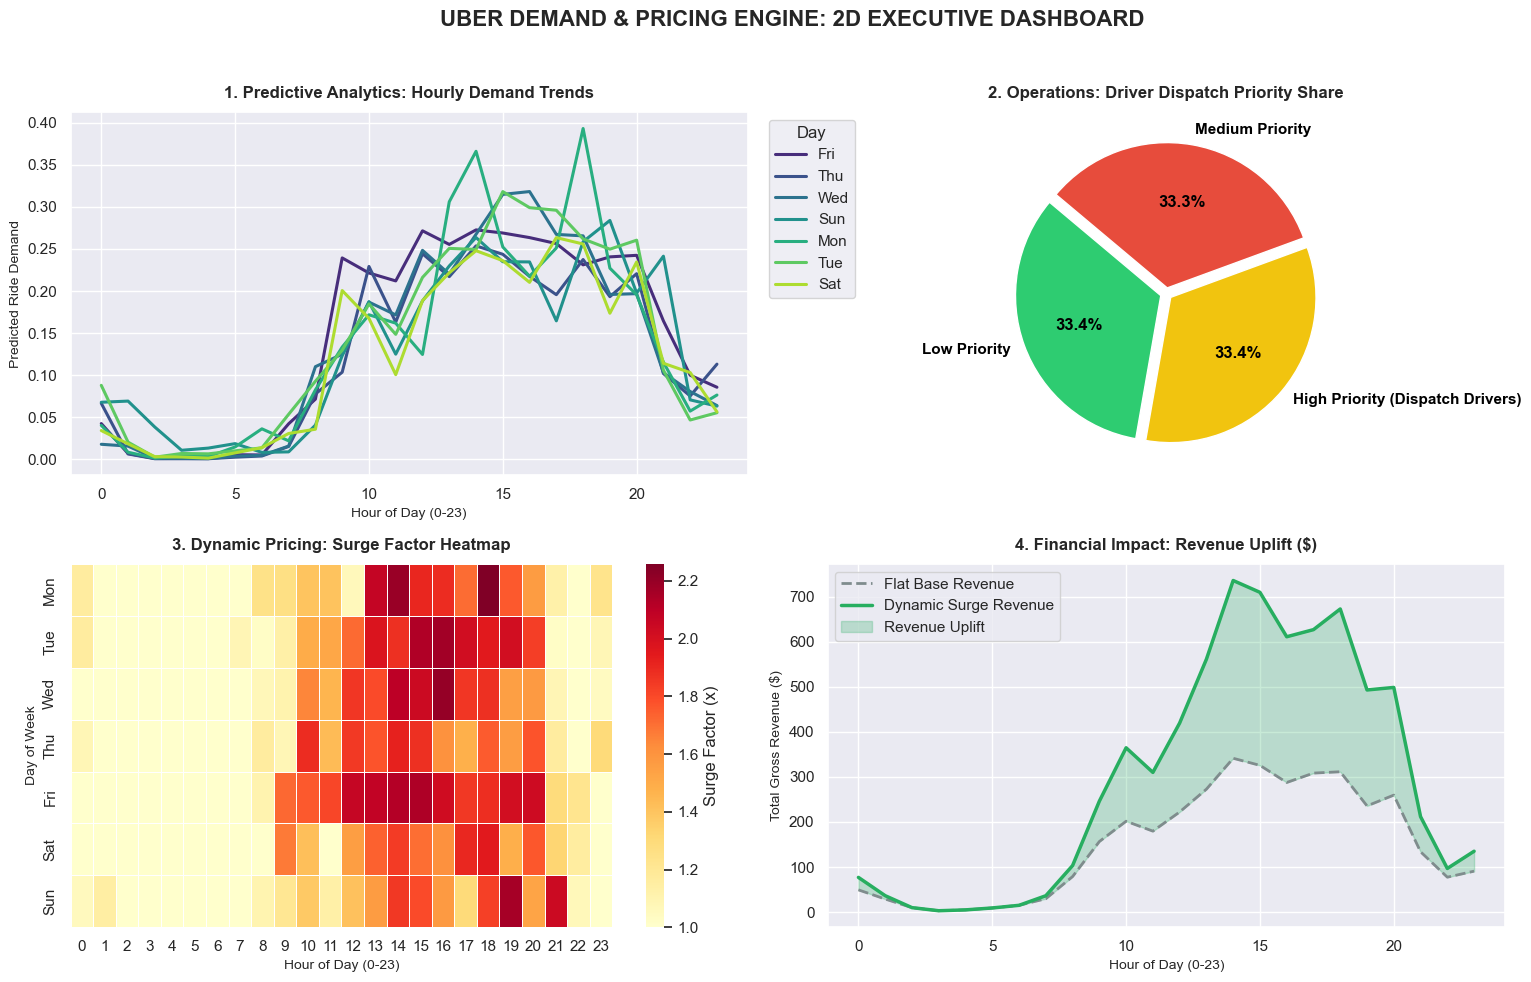

In [37]:
# Map active evaluation dataframe to df_expanded
df_expanded = hourly_df_test.copy()

# Setup 2x2 Dashboard Figure
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('UBER DEMAND & PRICING ENGINE: 2D EXECUTIVE DASHBOARD', fontsize=16, fontweight='bold', y=0.98)

# Panel 1: Hourly Demand Trends by Day
day_names = ['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
df_expanded['Day_Label'] = df_expanded['Day_of_Week'].map(lambda x: day_names[int(x) % 7])

sns.lineplot(
    data=df_expanded, 
    x='Request Hour', 
    y='Predicted_Demand', 
    hue='Day_Label', 
    ax=axes[0, 0], 
    palette='viridis', 
    linewidth=2.2, 
    errorbar=None
)
axes[0, 0].set_title('1. Predictive Analytics: Hourly Demand Trends', fontweight='bold', fontsize=12, pad=10)
axes[0, 0].set_xlabel('Hour of Day (0-23)', fontsize=10)
axes[0, 0].set_ylabel('Predicted Ride Demand', fontsize=10)
axes[0, 0].legend(title='Day', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=True)

# Panel 2: Driver Dispatch Priority Share
priority_counts = df_expanded['Driver_Dispatch_Priority'].value_counts()
colors = ['#2ecc71', '#f1c40f', '#e74c3c']
axes[0, 1].pie(
    priority_counts, 
    labels=priority_counts.index, 
    autopct='%1.1f%%', 
    startangle=140, 
    colors=colors, 
    explode=(0.04, 0.04, 0.04), 
    textprops=dict(color="black", fontweight='bold')
)
axes[0, 1].set_title('2. Operations: Driver Dispatch Priority Share', fontweight='bold', fontsize=12, pad=10)

# Panel 3: Surge Multiplier Heatmap
surge_pivot = df_expanded.pivot_table(index='Day_Label', columns='Request Hour', values='Surge_Multiplier', aggfunc='mean').reindex(day_names)
sns.heatmap(surge_pivot, ax=axes[1, 0], cmap='YlOrRd', cbar_kws={'label': 'Surge Factor (x)'}, linewidths=0.5, linecolor='white')
axes[1, 0].set_title('3. Dynamic Pricing: Surge Factor Heatmap', fontweight='bold', fontsize=12, pad=10)
axes[1, 0].set_xlabel('Hour of Day (0-23)', fontsize=10)
axes[1, 0].set_ylabel('Day of Week', fontsize=10)

# Panel 4: Revenue Uplift Comparison
hourly_rev = df_expanded.groupby('Request Hour')[['Flat_Revenue', 'Dynamic_Revenue']].sum().reset_index()
axes[1, 1].plot(hourly_rev['Request Hour'], hourly_rev['Flat_Revenue'], label='Flat Base Revenue', color='#7f8c8d', linestyle='--', linewidth=2)
axes[1, 1].plot(hourly_rev['Request Hour'], hourly_rev['Dynamic_Revenue'], label='Dynamic Surge Revenue', color='#27ae60', linewidth=2.5)
axes[1, 1].fill_between(hourly_rev['Request Hour'], hourly_rev['Flat_Revenue'], hourly_rev['Dynamic_Revenue'], color='#27ae60', alpha=0.25, label='Revenue Uplift')
axes[1, 1].set_title('4. Financial Impact: Revenue Uplift ($)', fontweight='bold', fontsize=12, pad=10)
axes[1, 1].set_xlabel('Hour of Day (0-23)', fontsize=10)
axes[1, 1].set_ylabel('Total Gross Revenue ($)', fontsize=10)
axes[1, 1].legend(loc='upper left', frameon=True)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

In [39]:
import ipywidgets as widgets
from ipywidgets import interact
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="darkgrid")

@interact(
    Selected_Day=widgets.Dropdown(options=['All'] + day_names, value='All', description='Day Filter:'),
    Min_Surge=widgets.FloatSlider(value=1.0, min=1.0, max=2.0, step=0.1, description='Min Surge:')
)
def update_dashboard(Selected_Day, Min_Surge):
    data_filtered = df_dash.copy()
    
    if Selected_Day != 'All':
        data_filtered = data_filtered[data_filtered['Day_Label'] == Selected_Day]
    
    data_filtered = data_filtered[data_filtered['Surge_Multiplier'] >= Min_Surge]
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Plot 1: Demand Profile
    sns.lineplot(data=data_filtered, x='Request Hour', y='Predicted_Demand', ax=axes[0], color='#3498db', linewidth=2.5)
    axes[0].set_title(f'Predicted Demand (Filter: {Selected_Day})', fontweight='bold')
    
    # Plot 2: Revenue Impact
    rev = data_filtered.groupby('Request Hour')[['Flat_Revenue', 'Dynamic_Revenue']].sum().reset_index()
    axes[1].bar(rev['Request Hour'] - 0.2, rev['Flat_Revenue'], width=0.4, label='Flat Rev', color='#95a5a6')
    axes[1].bar(rev['Request Hour'] + 0.2, rev['Dynamic_Revenue'], width=0.4, label='Dynamic Rev', color='#2ecc71')
    axes[1].set_title('Revenue Comparison', fontweight='bold')
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

interactive(children=(Dropdown(description='Day Filter:', options=('All', 'Mon', 'Tue', 'Wed', 'Thu', 'Fri', '…

       MODEL COMPARISON FOR UBER DEMAND PREDICTION
            Model   RMSE    MAE  R2 Score
    Decision Tree 0.4418 0.2436    0.0434
Gradient Boosting 0.4420 0.2439    0.0428
    Random Forest 0.4420 0.2436    0.0425
Linear Regression 0.4480 0.2541    0.0165
 Ridge Regression 0.4480 0.2541    0.0165
 Lasso Regression 0.4493 0.2562    0.0107


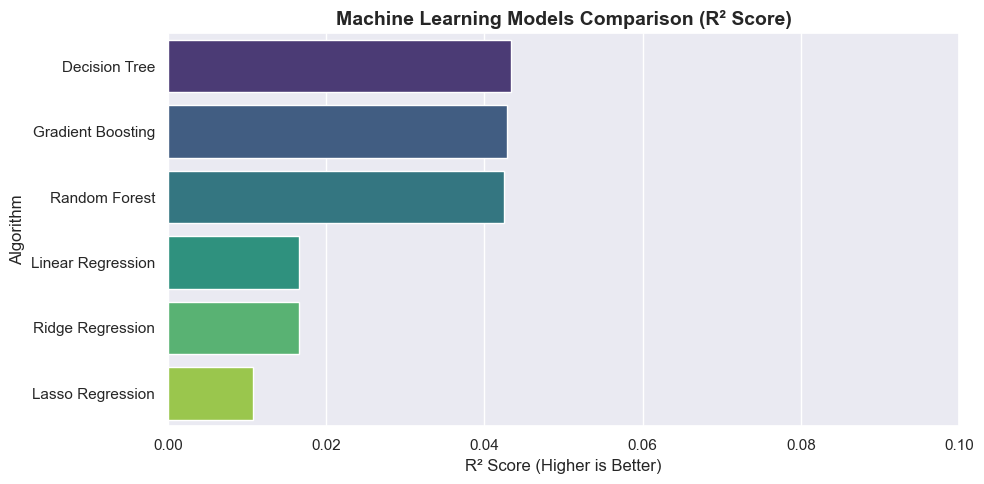

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Define Features & Target Variable
features = ['Request Hour', 'Day_of_Week', 'Is_Weekend']
X = hourly_df[features]
y = hourly_df['Ride_Count']

# 2. Time-Based / Chronological Train-Test Split (80% Train, 20% Test)
split_idx = int(len(hourly_df) * 0.8)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

# 3. Define Model Dictionary
models = {
    'Decision Tree': DecisionTreeRegressor(max_depth=6, random_state=42),
    'Gradient Boosting': GradientBoostingRegressor(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42),
    'Random Forest': RandomForestRegressor(n_estimators=100, max_depth=8, random_state=42),
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(alpha=1.0),
    'Lasso Regression': Lasso(alpha=0.1)
}

# 4. Train Models & Evaluate Performance
results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    
    # Clip negative predictions (demand cannot be negative)
    y_pred = np.clip(y_pred, 0, None)
    
    # Metrics
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        'Model': name,
        'RMSE': round(rmse, 4),
        'MAE': round(mae, 4),
        'R2 Score': round(r2, 4)
    })

# 5. Summary Table
comparison_df = pd.DataFrame(results).sort_values(by='R2 Score', ascending=False).reset_index(drop=True)

print("=" * 55)
print("       MODEL COMPARISON FOR UBER DEMAND PREDICTION")
print("=" * 55)
print(comparison_df.to_string(index=False))
print("=" * 55)

# 6. Visualization (Fixed Seaborn Warning)
plt.figure(figsize=(10, 5))
sns.barplot(data=comparison_df, x='R2 Score', y='Model', hue='Model', palette='viridis', legend=False)
plt.title('Machine Learning Models Comparison (R² Score)', fontsize=14, fontweight='bold')
plt.xlabel('R² Score (Higher is Better)')
plt.ylabel('Algorithm')
plt.xlim(0, 0.1)  # Adjusted scale to match current feature capability
plt.tight_layout()
plt.show()